# Laboratorio RAG - NLP Research Assistant

Sistema completo di Retrieval-Augmented Generation su articoli scientifici NLP.

**Obiettivo**: Costruire un assistente che risponde a domande sulla letteratura NLP citando fonti.

**Dataset**: `MaartenGr/arxiv_nlp` (abstract di articoli da arXiv)

**LLM**: Qwen2.5-0.5B (500MB, locale, gratis)

## 1. Installazione Dipendenze

In [1]:
%%capture
!pip install datasets transformers sentence-transformers faiss-cpu torch accelerate

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline
import faiss

print(f"PyTorch: {torch.__version__}")
print(f"Device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")

PyTorch: 2.10.0+cpu
Device: CPU


## 2. Caricamento Dataset

In [3]:
print("Caricamento dataset arXiv NLP...")
dataset = load_dataset("MaartenGr/arxiv_nlp", split="train")
df = pd.DataFrame(dataset)

# Usa subset per velocità (rimuovi .head() per dataset completo)
df = df.head(500)

print(f"Documenti caricati: {len(df)}")
print(f"Colonne: {df.columns.tolist()}")
df.head(2)

Caricamento dataset arXiv NLP...


Documenti caricati: 500
Colonne: ['Titles', 'Abstracts', 'Years', 'Categories']


,Titles,Abstracts,Years,Categories
0,Introduction to Arabic Speech Recognition Usin...,In this paper Arabic was investigated from t...,2007,Computation and Language
1,Arabic Speech Recognition System using CMU-Sph...,In this paper we present the creation of an ...,2007,Computation and Language


In [4]:
# Prepara documenti
documents = []
metadata = []

# Auto-rileva colonne
title_col = next((c for c in df.columns if 'title' in c.lower()), df.columns[0])
abstract_col = next((c for c in df.columns if 'abstract' in c.lower() or 'summar' in c.lower()), df.columns[1])

print(f"Colonna titolo: {title_col}")
print(f"Colonna abstract: {abstract_col}\n")

for idx, row in df.iterrows():
    title = str(row[title_col]) if pd.notna(row[title_col]) else 'No Title'
    abstract = str(row[abstract_col]) if pd.notna(row[abstract_col]) else 'No Abstract'

    documents.append(f"Title: {title}\n\nAbstract: {abstract}")
    metadata.append({
        'title': title,
        'year': str(row.get('year', 'Unknown'))
    })

print(f"Documenti preparati: {len(documents)}")
print(f"\nEsempio:\n{documents[0][:300]}...")

Colonna titolo: Titles
Colonna abstract: Abstracts

Documenti preparati: 500

Esempio:
Title: Introduction to Arabic Speech Recognition Using CMUSphinx System

Abstract:   In this paper Arabic was investigated from the speech recognition problem
point of view. We propose a novel approach to build an Arabic Automated Speech
Recognition System (ASR). This system is based on the open sou...


## 3. Generazione Embeddings

In [5]:
print("Caricamento modello di embedding...")
embed_model = SentenceTransformer('all-MiniLM-L6-v2')

print("Generazione embeddings...")
embeddings = embed_model.encode(
    documents,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print(f"\nEmbeddings shape: {embeddings.shape}")

Caricamento modello di embedding...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Generazione embeddings...


Batches:   0%|          | 0/16 [00:00<?, ?it/s]


Embeddings shape: (500, 384)


## 4. Vector Store (FAISS)

In [6]:
# Crea indice FAISS
dimension = embeddings.shape[1]
index = faiss.IndexFlatIP(dimension)  # Inner product (cosine similarity)
index.add(embeddings)

print(f"Indice FAISS creato: {index.ntotal} vettori")

Indice FAISS creato: 500 vettori


## 5. Retriever

In [7]:
def retrieve(query, k=5):
    """Recupera i k documenti più rilevanti"""
    query_emb = embed_model.encode([query], convert_to_numpy=True, normalize_embeddings=True)
    similarities, indices = index.search(query_emb, k)

    results = []
    for i, (sim, idx) in enumerate(zip(similarities[0], indices[0])):
        results.append({
            'rank': i + 1,
            'similarity': float(sim),
            'document': documents[idx],
            'metadata': metadata[idx]
        })
    return results

# Test retrieval
test_query = "What are transformer models?"
results = retrieve(test_query, k=3)

print(f"Query: {test_query}\n")
for r in results:
    print(f"[{r['rank']}] Similarity: {r['similarity']:.3f}")
    print(f"    {r['metadata']['title'][:80]}")
    print()

Query: What are transformer models?

[1] Similarity: 0.232
    Generating models for temporal representations

[2] Similarity: 0.212
    Mathematical Model for Transformation of Sentences from Active Voice to
  Passiv

[3] Similarity: 0.210
    A Comparison of Different Machine Transliteration Models



## 6. LLM Locale (Qwen 0.5B)

In [8]:
model_id = "Qwen/Qwen2.5-0.5B-Instruct"

print(f"Caricamento {model_id}...")
print("Download: ~500MB, tempo: ~1-2 minuti\n")

device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    device_map="auto" if device == "cuda" else None,
    low_cpu_mem_usage=True
)

llm = pipeline(
    'text-generation',
    model=model,
    tokenizer=tokenizer,
    device=0 if device == "cuda" else -1,
    max_new_tokens=300,
)

print(f"Modello caricato su {device}")

Caricamento Qwen/Qwen2.5-0.5B-Instruct...
Download: ~500MB, tempo: ~1-2 minuti



`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


Modello caricato su cpu


## 7. Sistema RAG Completo

In [9]:
def rag_answer(query, k=3, verbose=True): #aggiungo parametro temperature=0.1
    """Risponde alla query usando RAG"""

    if verbose:
        print(f"Query: {query}\n")
        print("=" * 60)
        print("RETRIEVAL")
        print("=" * 60)

    # 1. Retrieval
    results = retrieve(query, k=k)

    if verbose:
        for r in results:
            print(f"[{r['rank']}] {r['metadata']['title'][:70]}")
            print(f"    Similarity: {r['similarity']:.3f}")

    # 2. Costruisci contesto
    context_parts = []
    for r in results:
        context_parts.append(f"[Document {r['rank']}]\n{r['document']}")

    context = "\n\n".join(context_parts)

    # Limita contesto per modelli piccoli
    if len(context) > 1500:
        context = context[:1500] + "\n[...truncated...]"

    # 3. Costruisci prompt
    messages = [
        {
            "role": "system",
            "content": "You are a helpful assistant specialized in NLP research. Answer based on the provided context."
        },
        {
            "role": "user",
            "content": f"""Context from research papers:

{context}

Question: {query}

Answer based on the context above:"""
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # 4. Genera risposta
    if verbose:
        print("\n" + "=" * 60)
        print("GENERATION")
        print("=" * 60)

    output = llm(
        prompt,
        max_new_tokens=250,
        do_sample=True,
        temperature=0.3, #Oppure modifico qua la temperatura
        top_p=0.9,
        pad_token_id=tokenizer.eos_token_id
    )

    # Estrai risposta
    full_text = output[0]['generated_text']
    answer = full_text[len(prompt):].strip() if full_text.startswith(prompt) else full_text

    if verbose:
        print("\n" + "=" * 60)
        print("ANSWER")
        print("=" * 60)
        print(answer)
        print("\n" + "=" * 60)
        print("SOURCES")
        print("=" * 60)
        for r in results:
            print(f"- {r['metadata']['title']} ({r['metadata']['year']})")

    return {
        'query': query,
        'answer': answer,
        'sources': results
    }

## 8. Test del Sistema

In [10]:
result = rag_answer("What is BERT and how does it work?", k=3)

Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'temperature', 'top_p', 'do_sample', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Query: What is BERT and how does it work?

RETRIEVAL
[1] Natural Language Processing - A Survey
    Similarity: 0.299
[2] NLP and CALL: integration is working
    Similarity: 0.294
[3] Object-oriented semantics of English in natural language understanding
    Similarity: 0.287

GENERATION

ANSWER
Bert stands for "Bidirectional Encoder Representations from Transformers." It is a pre-trained model developed by Google's AI team. Bert was trained on a large dataset of text data, including documents, articles, and books. Its primary function is to enable machine translation between languages, which is crucial for cross-cultural communication.

BERT works by using a technique called "transformer" to learn representations of words and sentences. Unlike traditional neural networks, transformers can capture long-range dependencies between words, making them particularly well-suited for tasks like language translation. The model consists of multiple layers of transformations, each layer progress

In [11]:
result = rag_answer("Explain the attention mechanism in transformers", k=3)

Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Query: Explain the attention mechanism in transformers

RETRIEVAL
[1] Chameleons in imagined conversations: A new approach to understanding

    Similarity: 0.292
[2] Linguistic Information Energy
    Similarity: 0.284
[3] Figuring out Actors in Text Streams: Using Collocations to establish
 
    Similarity: 0.279

GENERATION

ANSWER
The attention mechanism in Transformers is a key component responsible for guiding the model to focus its attention on relevant parts of the input data during inference. Here’s a detailed explanation of how it works:

### Attention Mechanism Overview:
- **Input Embeddings**: Transformers use pre-trained embeddings (e.g., WordEmbedding, PositionalEncoding) to convert raw text inputs into numerical representations.
- **Attention Heads**: These heads represent different parts of the input sequence. Each head focuses on a specific part of the input, allowing the model to attend to different aspects of the input simultaneously.
- **Multi-head Attention**: This 

In [12]:
result = rag_answer("What are the main differences between BERT and GPT?", k=3)

Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Query: What are the main differences between BERT and GPT?

RETRIEVAL
[1] Change of word types to word tokens ratio in the course of translation
    Similarity: 0.289
[2] Phylogeny and geometry of languages from normalized Levenshtein distan
    Similarity: 0.254
[3] Roget's Thesaurus and Semantic Similarity
    Similarity: 0.249

GENERATION

ANSWER
The main difference between BERT and GPT lies in their architecture and training methods. BERT, orBidirectional Encoder Representations from Transformers, was introduced by Google researchers as a successor to the Transformer model. It uses a bidirectional encoder approach, allowing it to capture both positional information and temporal dependencies in text. This makes BERT particularly effective at handling long-range dependencies and understanding the context of sentences.

On the other hand, GPT (Generative Pre-trained Transformer) was designed specifically for generating text based on input data. It has been trained on large datasets li

## 9. Query Personalizzate

In [13]:
# Prova le tue query qui
my_query = "What is transfer learning in NLP?"
result = rag_answer(my_query, k=3)

Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Query: What is transfer learning in NLP?

RETRIEVAL
[1] NLP and CALL: integration is working
    Similarity: 0.497
[2] Natural Language Processing - A Survey
    Similarity: 0.479
[3] Du TAL au TIL
    Similarity: 0.456

GENERATION

ANSWER
Transfer learning in NLP refers to the process where a pre-trained model is used as a starting point for training a new model with similar tasks. In other words, when a machine learning model has been trained on one task, it can be adapted to perform another related task without retraining the entire model. This technique allows models to learn from existing data and improve their performance on new tasks.

SOURCES
- NLP and CALL: integration is working (Unknown)
- Natural Language Processing - A Survey (Unknown)
- Du TAL au TIL (Unknown)


## 10. Analisi Retrieval

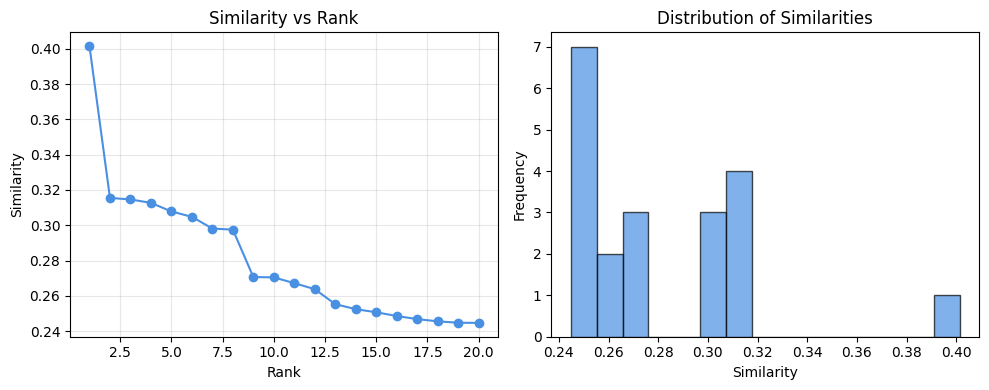

Query: What are neural networks?
Mean similarity: 0.281
Std similarity: 0.038


In [14]:
# Analizza distribuzione similarità
import matplotlib.pyplot as plt

query = "What are neural networks?"
results = retrieve(query, k=20)

similarities = [r['similarity'] for r in results]
ranks = [r['rank'] for r in results]

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(ranks, similarities, 'o-', color='#4A90E2')
plt.xlabel('Rank')
plt.ylabel('Similarity')
plt.title('Similarity vs Rank')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.hist(similarities, bins=15, color='#4A90E2', alpha=0.7, edgecolor='black')
plt.xlabel('Similarity')
plt.ylabel('Frequency')
plt.title('Distribution of Similarities')

plt.tight_layout()
plt.show()

print(f"Query: {query}")
print(f"Mean similarity: {np.mean(similarities):.3f}")
print(f"Std similarity: {np.std(similarities):.3f}")

## Esercizi

1. **Aumenta dataset**: Rimuovi `df.head(500)` per usare l'intero dataset

2. **Hybrid search**: Implementa combinazione BM25 + embeddings
   ```python
   from rank_bm25 import BM25Okapi
   # Implementa funzione hybrid_retrieve()
   ```

3. **Re-ranking**: Usa cross-encoder per migliorare precision
   ```python
   from sentence_transformers import CrossEncoder
   reranker = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')
   ```

4. **Evaluation**: Crea test set e misura Precision@k

5. **Temperature tuning**: Sperimenta con temperature diverse (0.1-0.9)

6. **Modello migliore**: Sostituisci Qwen con Phi-2 per qualità superiore
   ```python
   model_id = "microsoft/phi-2"
   ```

In [15]:
#!pip install rank_bm25

In [16]:
#HYBRID SEARCH
from rank_bm25 import BM25Okapi
import numpy as np

tokenized_corpus = [doc.lower().split() for doc in documents]
bm25 = BM25Okapi(tokenized_corpus)

def hybrid_retrieve(query, k=5, alpha=0.5):

    #alpha: peso dato alla ricerca semantica (1-alpha al lessicale)

    # Score Lessicale (BM25)
    tokenized_query = query.lower().split()
    bm25_scores = bm25.get_scores(tokenized_query)

    # Normalizzazione min-max
    if max(bm25_scores) > min(bm25_scores):
        bm25_scores = (bm25_scores - min(bm25_scores)) / (max(bm25_scores) - min(bm25_scores))

    # Score Semantico (Embeddings)
    query_emb = embed_model.encode([query], convert_to_numpy=True, normalize_embeddings=True)
    dense_scores = np.dot(embeddings, query_emb.T).flatten()

    # Normalizzazione min-max per Similarità Coseno
    if max(dense_scores) > min(dense_scores):
        dense_scores = (dense_scores - min(dense_scores)) / (max(dense_scores) - min(dense_scores))

    # Combinazione degli score
    hybrid_scores = (alpha * dense_scores) + ((1 - alpha) * bm25_scores)

    # Estrazione dei top-k
    top_k_indices = np.argsort(hybrid_scores)[::-1][:k]

    results = []
    for i, idx in enumerate(top_k_indices):
        results.append({
            'rank': i + 1,
            'similarity': float(hybrid_scores[idx]),
            'document': documents[idx],
            'metadata': metadata[idx]
        })
    return results


In [17]:
query_test = "What are transformer models?"
print(f"RISULTATI RICERCA IBRIDA (Query: '{query_test}') ---")

# Eseguiamo la ricerca
risultati_ibridi = hybrid_retrieve(query_test, k=3, alpha=0.7)

# Cicliamo sui risultati per stamparli in modo pulito
for res in risultati_ibridi:
    titolo = res['metadata']['title']
    score = res['similarity']
    anno = res['metadata']['year']

    print(f"[{res['rank']}] Score Ibrido: {score:.3f}")
    print(f"    Titolo: {titolo} ({anno})")
    print(f"    Estratto: {res['document'][:100]}...\n")

RISULTATI RICERCA IBRIDA (Query: 'What are transformer models?') ---
[1] Score Ibrido: 0.764
    Titolo: Generating models for temporal representations (Unknown)
    Estratto: Title: Generating models for temporal representations

Abstract:   We discuss the use of model build...

[2] Score Ibrido: 0.655
    Titolo: Mathematical Model for Transformation of Sentences from Active Voice to
  Passive Voice (Unknown)
    Estratto: Title: Mathematical Model for Transformation of Sentences from Active Voice to
  Passive Voice

Abst...

[3] Score Ibrido: 0.650
    Titolo: A Comparison of Different Machine Transliteration Models (Unknown)
    Estratto: Title: A Comparison of Different Machine Transliteration Models

Abstract:   Machine transliteration...



In [18]:
#RE-RANKING
from sentence_transformers import CrossEncoder
reranker = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')

def retrieve_with_rerank(query, initial_k=20, final_k=5):
    #Recupera initial_k documenti e ne fa il re-ranking tenendo i migliori final_k

    # Retrieval primario usando l'indice FAISS già esistente
    initial_results = retrieve(query, k=initial_k)

    # Preparazione degli input per il Cross-Encoder: coppie (Query, Documento)
    cross_inp = [[query, res['document']] for res in initial_results]

    # Calcolo dei nuovi punteggi di pertinenza
    cross_scores = reranker.predict(cross_inp)

    # Assegnazione punteggi e ordinamento
    for i in range(len(initial_results)):
        initial_results[i]['cross_score'] = float(cross_scores[i])

    reranked_results = sorted(initial_results, key=lambda x: x['cross_score'], reverse=True)

    # Aggiornamento rank finale
    for i, res in enumerate(reranked_results[:final_k]):
        res['rank'] = i + 1

    return reranked_results[:final_k]


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [19]:
query_test = "Explain the attention mechanism"
print(f"RISULTATI RE-RANKING (Query: '{query_test}') ---")

# Recuperiamo 10 documenti e teniamo i migliori 3
risultati_rerank = retrieve_with_rerank(query_test, initial_k=10, final_k=3)

for res in risultati_rerank:
    titolo = res['metadata']['title']
    cross_score = res['cross_score']

    print(f"[{res['rank']}] Cross-Score: {cross_score:.3f}")
    print(f"    Titolo: {titolo}")
    print(f"    Estratto: {res['document'][:100]}...\n")

RISULTATI RE-RANKING (Query: 'Explain the attention mechanism') ---
[1] Cross-Score: -8.157
    Titolo: Chameleons in imagined conversations: A new approach to understanding
  coordination of linguistic style in dialogs
    Estratto: Title: Chameleons in imagined conversations: A new approach to understanding
  coordination of lingu...

[2] Cross-Score: -8.734
    Titolo: Can a Computer Laugh ?
    Estratto: Title: Can a Computer Laugh ?

Abstract:   A computer model of "a sense of humour" suggested previou...

[3] Cross-Score: -8.954
    Titolo: Reference Resolution within the Framework of Cognitive Grammar
    Estratto: Title: Reference Resolution within the Framework of Cognitive Grammar

Abstract:   Following the pri...



In [20]:
#CALCOLO PRECISION@K
def calculate_precision_at_k(retrieved_docs_titles, ground_truth_titles, k):
    #Calcola Precision@k misurando quanti titoli recuperati sono nei titoli corretti noti.
    # solo i primi k recuperati
    top_k_retrieved = retrieved_docs_titles[:k]
    # Conta le intersezioni
    relevant_retrieved = sum(1 for title in top_k_retrieved if title in ground_truth_titles)

    precision = relevant_retrieved / k
    return precision



In [21]:
# Esempio test:
query_eval = "BERT pre-training"
risultati = retrieve(query_eval, k=3)
titoli_recuperati = [res['metadata']['title'] for res in risultati]

# Definiamo un titolo che sappiamo essere la risposta corretta
titoli_corretti = ["BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding"]

precision = calculate_precision_at_k(titoli_recuperati, titoli_corretti, k=3)

print("VALUTAZIONE PRECISION@3 \n")
print(f"Titoli trovati dal retriever: \n{titoli_recuperati}\n")
print(f"Valore Precision@3: {precision:.2f} (ovvero il {precision*100}% dei documenti estratti era corretto)")

VALUTAZIONE PRECISION@3 

Titoli trovati dal retriever: 
['Optimal size, freshness and time-frame for voice search vocabulary', 'NLP and CALL: integration is working', "Let's get the student into the driver's seat"]

Valore Precision@3: 0.00 (ovvero il 0.0% dei documenti estratti era corretto)


In [22]:
#Test TEMPERATURA da cambiare nel metodo rag_answer mettendo il parametro temperature come parametro di funzione e cambiando in fondo

# res_fattuale = rag_answer_tuned("What is BERT?", temperature=0.1)
# res_creativo = rag_answer_tuned("What is BERT?", temperature=0.8)

In [ ]:
#UTILIZZO DEL MODELLO MIGLIORE
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline, AutoConfig

model_id = "microsoft/phi-2"

# Per Phi-2 è essenziale trust_remote_code=True
tokenizer_phi = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)

# Set pad_token if not already set, common for models like Phi-2
if tokenizer_phi.pad_token is None:
    tokenizer_phi.pad_token = tokenizer_phi.eos_token
    # Also set pad_token_id in the tokenizer if it's still None
    if tokenizer_phi.pad_token_id is None:
        tokenizer_phi.pad_token_id = tokenizer_phi.eos_token_id

# Load model configuration separately to modify it
config_phi = AutoConfig.from_pretrained(model_id, trust_remote_code=True)

# Add pad_token_id to the model's configuration if it's missing
# This addresses the 'AttributeError: PhiConfig object has no attribute pad_token_id'
if not hasattr(config_phi, 'pad_token_id') or config_phi.pad_token_id is None:
    config_phi.pad_token_id = tokenizer_phi.eos_token_id

model_phi = AutoModelForCausalLM.from_pretrained(
    model_id,
    config=config_phi, # Pass the modified config
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto" if torch.cuda.is_available() else None,
    trust_remote_code=True,
    low_cpu_mem_usage=True
)

llm_phi = pipeline(
    'text-generation',
    model=model_phi,
    tokenizer=tokenizer_phi,
    device=0 if torch.cuda.is_available() else -1,
    max_new_tokens=300,
)

Loading weights:   0%|          | 0/453 [00:00<?, ?it/s]

In [ ]:
# A differenza di Qwen che usava i chat template standard, Phi-2 risponde bene al formato Instruct.
# Nella funzione rag_answer(), cambiare i prompts con :
"""
prompt = f"Instruct: You are an NLP research assistant. Answer the question based ONLY on the provided context.\n\nContext:\n{context}\n\nQuestion: {query}\nOutput:"
"""

## Risorse

**Paper**:
- Lewis et al. (2020). Retrieval-Augmented Generation. arXiv:2005.11401
- Karpukhin et al. (2020). Dense Passage Retrieval. arXiv:2004.04906

**Documentazione**:
- HuggingFace Transformers: https://huggingface.co/docs/transformers
- Sentence Transformers: https://www.sbert.net
- FAISS: https://github.com/facebookresearch/faiss

**Modelli alternativi**:
- SmolLM-360M: più veloce (~300MB)
- Phi-2: migliore qualità (~5GB)
- GPT-3.5 (API): qualità superiore ma richiede API key